# Lab Mid Exam - Computer Vision

Jawad Hassan - 0035

# Setup

Two photos that ship with scikit-image are used, so there is nothing to upload.
`coffee` is the colour image and `coins` is the image used for the segmentation tasks.

In [1]:
# libraries, images and the helpers every task below reuses

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

np.random.seed(0)

color = cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR)
gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
coins = data.coins()

# the 3x3 structuring element used by all the morphology tasks
kernel = np.ones((3, 3), np.uint8)


# draw any list of images side by side in one row
def show(images, titles):
    plt.figure(figsize=(4.5 * len(images), 4.5))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if img.ndim == 3:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        elif img.dtype == np.uint8:
            # fix the grey range to 0-255, otherwise matplotlib stretches every
            # image to full contrast on its own and the Task 3 comparison lies
            plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(img, cmap='gray')
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


# sprinkle random black and white dots on an image (salt and pepper noise)
def add_noise(img, amount=0.04):
    out = img.copy()
    n = int(amount * img.size)
    ys = np.random.randint(0, img.shape[0], n)
    xs = np.random.randint(0, img.shape[1], n)
    out[ys[:n // 2], xs[:n // 2]] = 0
    out[ys[n // 2:], xs[n // 2:]] = 255
    return out


print('colour image', color.shape, '  coins image', coins.shape)

colour image (400, 600, 3)   coins image (303, 384)


# Task 1: Image Transformation

Scale by 1.5x, then rotate 45 degrees, then translate 50 px right and 30 px down.
Each step is applied to the result of the step before it.

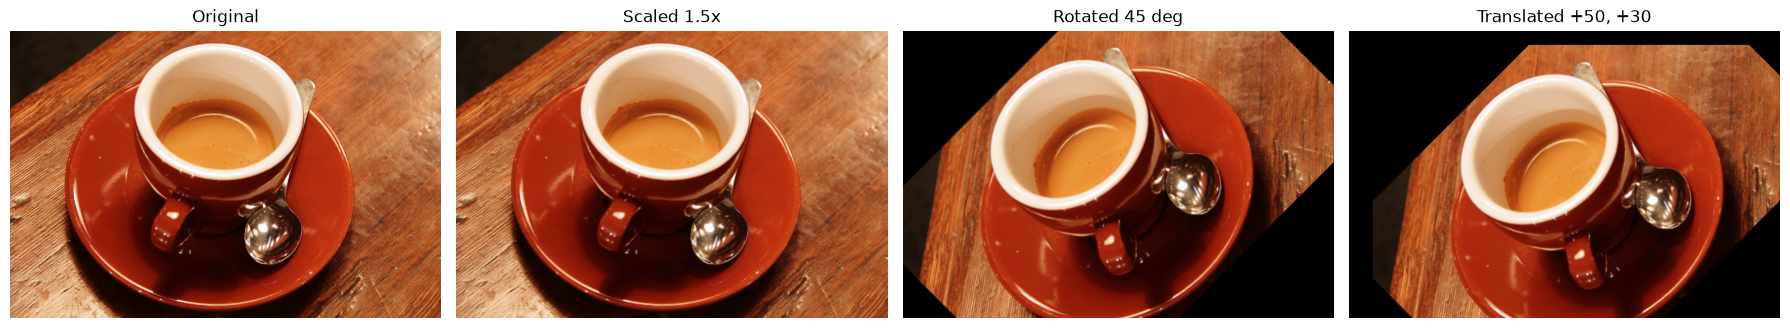

In [2]:
# a scale, a rotation and a translation applied one after the other

scaled = cv2.resize(color, None, fx=1.5, fy=1.5)

# rotate about the centre of the scaled image
h, w = scaled.shape[:2]
rotate_matrix = cv2.getRotationMatrix2D((w / 2, h / 2), 45, 1.0)
rotated = cv2.warpAffine(scaled, rotate_matrix, (w, h))

# a translation is just a shift of 50 in x and 30 in y
translate_matrix = np.float32([[1, 0, 50], [0, 1, 30]])
final = cv2.warpAffine(rotated, translate_matrix, (w, h))

show([color, scaled, rotated, final],
     ['Original', 'Scaled 1.5x', 'Rotated 45 deg', 'Translated +50, +30'])

# Task 2: Color Image Processing - Enhancement and Channel Manipulation

a. Convert to YCrCb, equalise the Y channel, merge back and display.
b. Pull out the green channel, median filter it, and put it back.

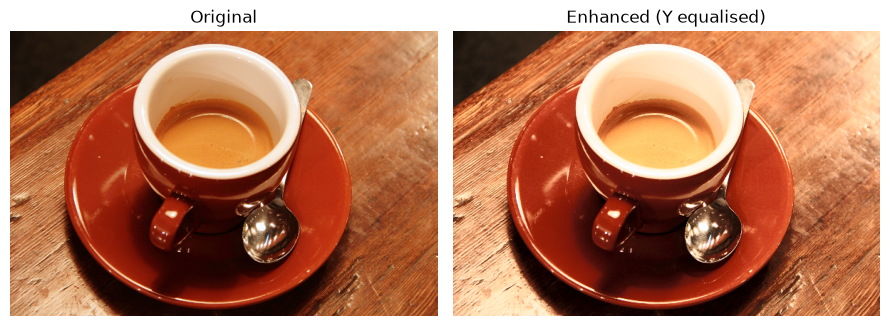

In [3]:
# Task 2a: Y holds the brightness, so equalising only Y fixes contrast without shifting colours

y, cr, cb = cv2.split(cv2.cvtColor(color, cv2.COLOR_BGR2YCrCb))
y_equalised = cv2.equalizeHist(y)
enhanced = cv2.cvtColor(cv2.merge([y_equalised, cr, cb]), cv2.COLOR_YCrCb2BGR)

show([color, enhanced], ['Original', 'Enhanced (Y equalised)'])

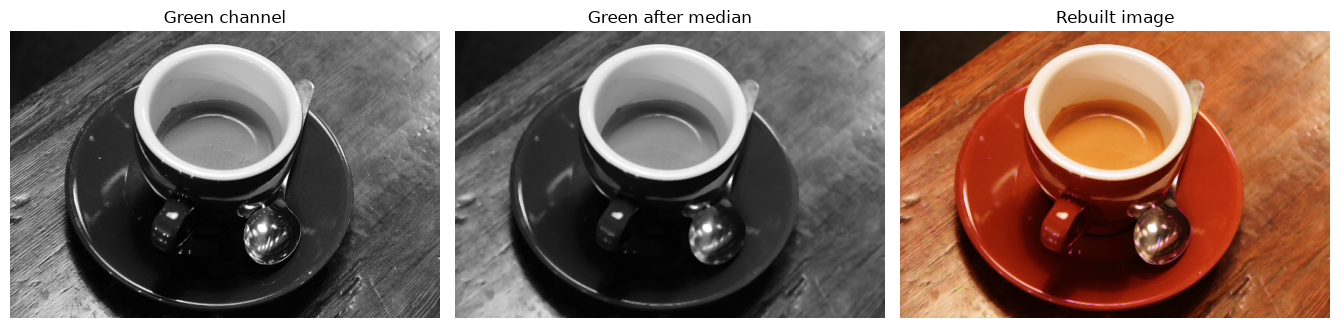

In [4]:
# Task 2b: median filter the green channel on its own, then rebuild the image with it

b, g, r = cv2.split(color)
green_filtered = cv2.medianBlur(g, 5)
denoised = cv2.merge([b, green_filtered, r])

show([g, green_filtered, denoised], ['Green channel', 'Green after median', 'Rebuilt image'])

# Task 3: Histogram Equalization and Adaptive Filtering

a. Global histogram equalisation vs CLAHE on a low contrast grayscale image.
b. A Gaussian filter vs an adaptive median filter.

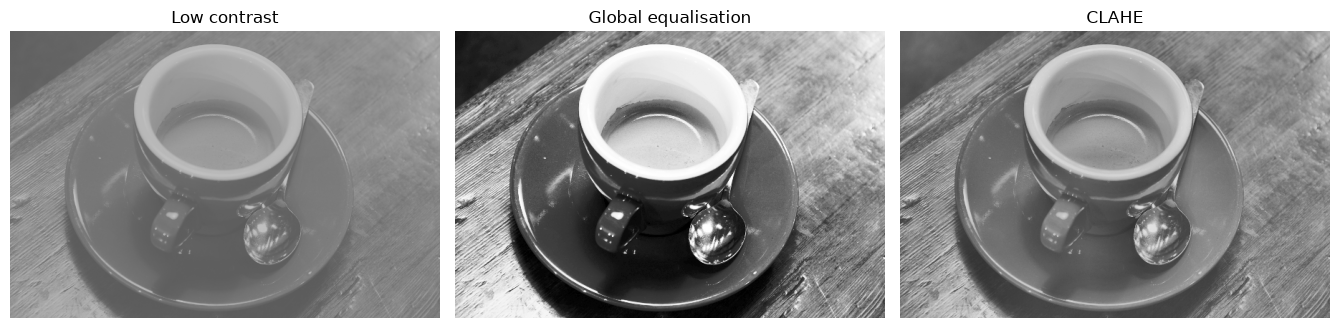

low contrast   contrast (std) = 23.2
global         contrast (std) = 73.3
clahe          contrast (std) = 34.3


In [5]:
# Task 3a: global equalisation stretches the whole image at once, CLAHE does it tile by tile

# squeeze the grey range first so the input really is low contrast
low = (gray * 0.4 + 90).astype(np.uint8)

global_eq = cv2.equalizeHist(low)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(low)

show([low, global_eq, clahe], ['Low contrast', 'Global equalisation', 'CLAHE'])

# a wider spread of pixel values means more contrast
for name, img in [('low contrast', low), ('global', global_eq), ('clahe', clahe)]:
    print(f'{name:14s} contrast (std) = {img.std():.1f}')

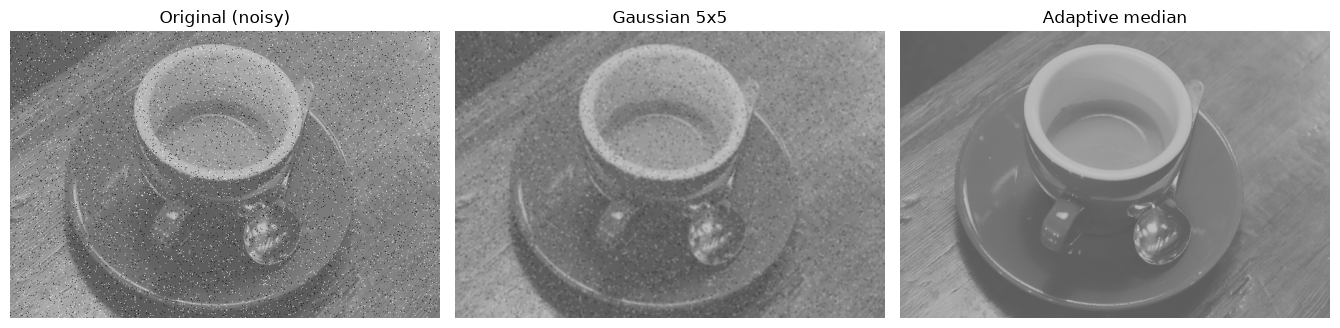

In [6]:
# Task 3b: a plain median uses one fixed window, an adaptive median grows the window

def adaptive_median(img, max_size=7):
    out = img.copy()
    for size in range(3, max_size + 1, 2):
        box = np.ones((size, size), np.uint8)
        # a pixel equal to its local min or max is almost certainly a noise dot
        is_noise = (img == cv2.erode(img, box)) | (img == cv2.dilate(img, box))
        out[is_noise] = cv2.medianBlur(img, size)[is_noise]
    return out


noisy = add_noise(low)
gaussian = cv2.GaussianBlur(noisy, (5, 5), 0)
adaptive = adaptive_median(noisy)

show([noisy, gaussian, adaptive], ['Original (noisy)', 'Gaussian 5x5', 'Adaptive median'])

# Task 4: Morphological Algorithms - Advanced Processing

a. Opening and closing on a noisy binary image.
b. Boundary extraction, where boundary = dilated - eroded, drawn on the original.

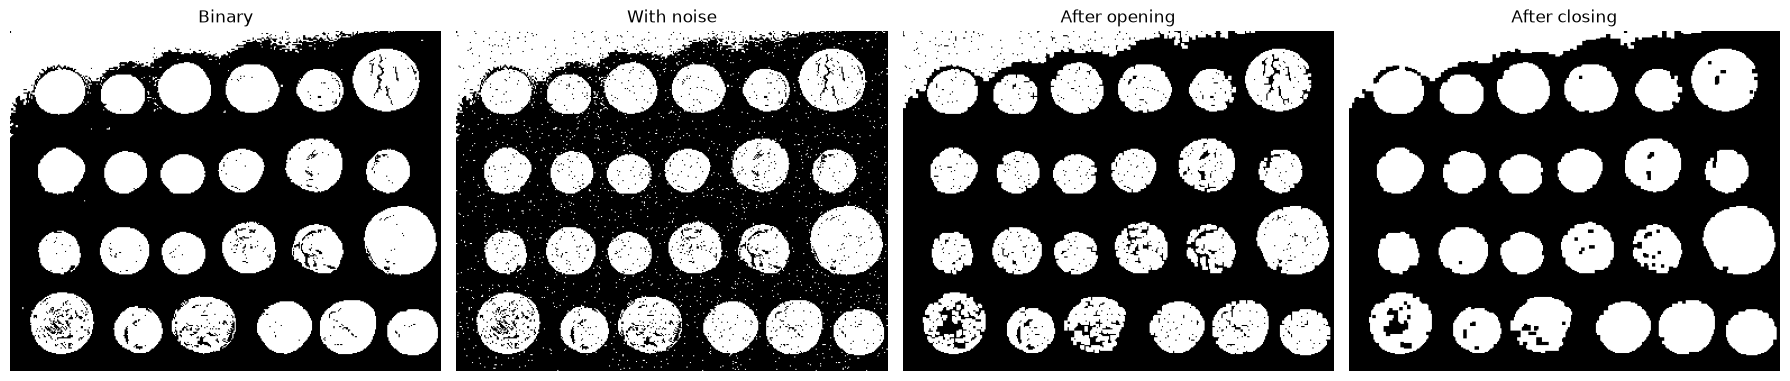

In [7]:
# Task 4a: opening removes small white specks, closing fills small black holes

_, binary = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
noisy_binary = add_noise(binary)

opening = cv2.morphologyEx(noisy_binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(opening, cv2.MORPH_CLOSE, kernel)

show([binary, noisy_binary, opening, closing],
     ['Binary', 'With noise', 'After opening', 'After closing'])

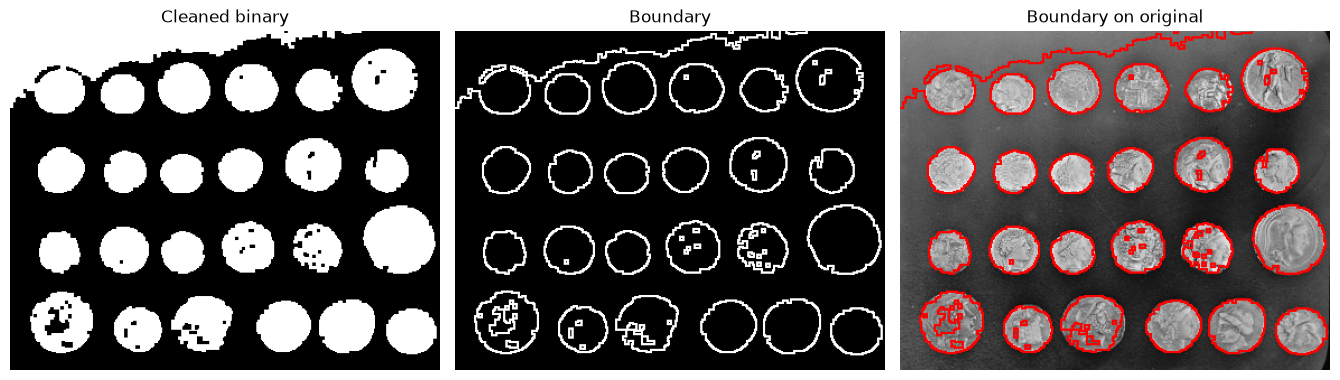

In [8]:
# Task 4b: the boundary is what dilation adds minus what erosion keeps

dilated = cv2.dilate(closing, kernel)
eroded = cv2.erode(closing, kernel)
boundary = cv2.subtract(dilated, eroded)

# paint those boundary pixels red on top of the original photo
overlay = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
overlay[boundary == 255] = (0, 0, 255)

show([closing, boundary, overlay], ['Cleaned binary', 'Boundary', 'Boundary on original'])

# Task 5: Edge Detection and Watershed Segmentation

a. Sobel in x and y, then the edge magnitude image.
b. Watershed segmentation with the object boundaries marked.

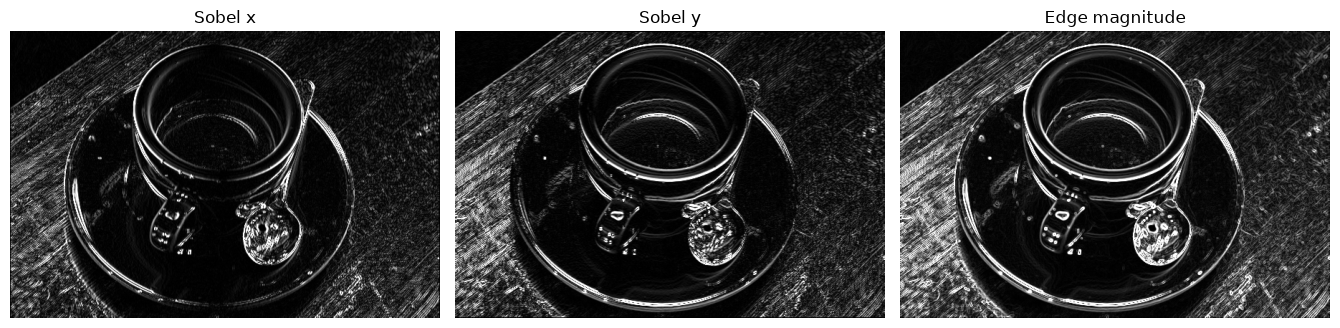

In [9]:
# Task 5a: Sobel measures how fast brightness changes, once across x and once down y

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# magnitude combines the two gradients, sqrt(x*x + y*y)
magnitude = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))

show([cv2.convertScaleAbs(sobel_x), cv2.convertScaleAbs(sobel_y), magnitude],
     ['Sobel x', 'Sobel y', 'Edge magnitude'])

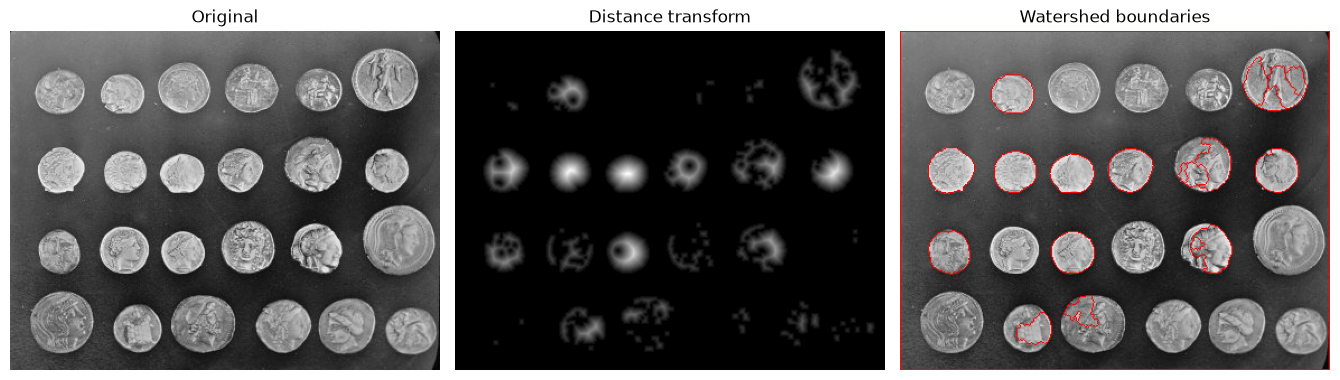

objects segmented: 20


In [10]:
# Task 5b: watershed can split touching coins, but only if we hand it good markers

# the photo is brighter on one side, so flatten the background before thresholding
flat = cv2.morphologyEx(coins, cv2.MORPH_TOPHAT,
                        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41)))
_, thresh = cv2.threshold(flat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
objects = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# distance from the nearest edge, so the deepest pixels are safely inside a coin
dist = cv2.distanceTransform(objects, cv2.DIST_L2, 5)
sure_fg = np.uint8(dist > 0.4 * dist.max()) * 255
sure_bg = cv2.dilate(objects, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)

# give every sure coin its own number and leave 0 for the pixels we are unsure about
count, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

coins_color = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(coins_color, markers)

# watershed writes -1 on every line it found between two objects
result = coins_color.copy()
result[markers == -1] = (0, 0, 255)

show([coins_color, dist, result], ['Original', 'Distance transform', 'Watershed boundaries'])
print('objects segmented:', markers.max() - 1)

# Task 6: Region-Based Segmentation with Morphology

a. Region growing from a single seed point.
b. The grown region cleaned up with morphological closing, shown step by step.

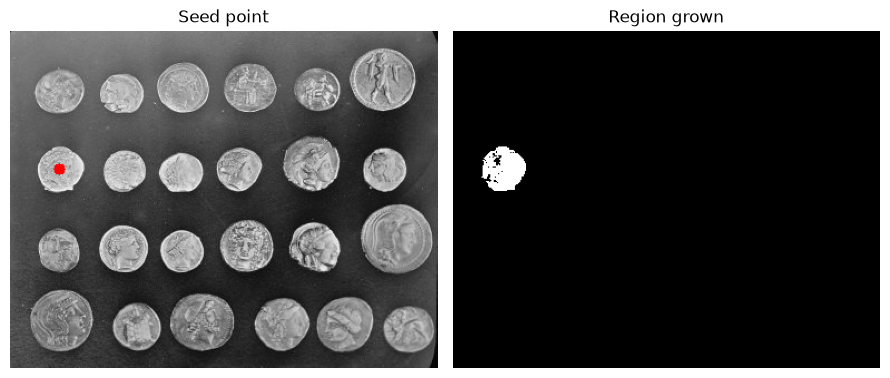

In [11]:
# Task 6a: region growing starts at one seed pixel and keeps adding similar neighbours

seed = (44, 124)  # an (x, y) point inside one coin

# floodFill is region growing, loDiff and upDiff say how different a neighbour may be
mask = np.zeros((coins.shape[0] + 2, coins.shape[1] + 2), np.uint8)
cv2.floodFill(coins.copy(), mask, seed, 255, loDiff=20, upDiff=20,
              flags=cv2.FLOODFILL_MASK_ONLY | (255 << 8))
region = mask[1:-1, 1:-1]

marked = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
cv2.circle(marked, seed, 5, (0, 0, 255), -1)

show([marked, region], ['Seed point', 'Region grown'])

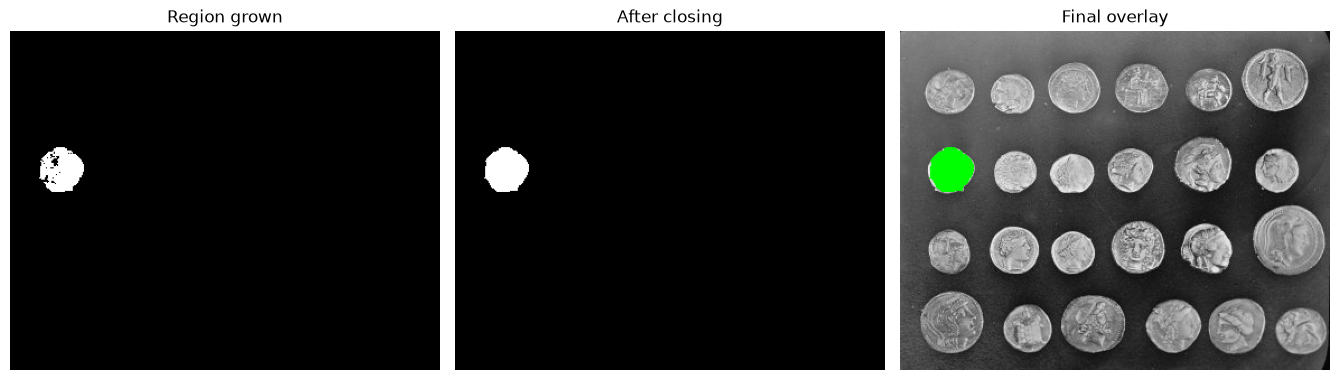

region pixels: 1117 -> after closing: 1206


In [12]:
# Task 6b: closing fills the gaps the growing missed and smooths the ragged edge

smooth = cv2.morphologyEx(region, cv2.MORPH_CLOSE,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))

final = marked.copy()
final[smooth == 255] = (0, 255, 0)

show([region, smooth, final], ['Region grown', 'After closing', 'Final overlay'])
print('region pixels:', (region == 255).sum(), '-> after closing:', (smooth == 255).sum())